# 07 — Train a controller through simulated practice

**Goal:** train the third candidate controller, a small Double DQN.
A neural network scores five possible actions. Practice stores examples in a replay buffer;
random replay batches train the network. A slowly updated target network stabilizes the targets.
The online network chooses the next action and the target network scores it: this is Double DQN.
Code: [dqn.py](../src/control/dqn.py), [train_dqn.py](../src/eval/train_dqn.py).
[Background: PyTorch's DQN tutorial](https://docs.pytorch.org/tutorials/intermediate/reinforcement_q_learning.html).

In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

project = Path.cwd()
if project.name == 'notebooks':
    project = project.parent
if str(project) not in sys.path:
    sys.path.insert(0, str(project))
from src.common import save_run, load_calibration, load_contexts
plt.rcParams.update({'figure.figsize': (8, 4), 'axes.spines.top': False, 'axes.spines.right': False})

def show_plot(name):
    plt.tight_layout()
    plt.savefig(folder / f'{name}.png', dpi=150)
    plt.show()

## 1. Define what the network can observe
Its 16 inputs are: five fatigue-belief probabilities, top-two classifier probabilities, entropy, predicted easiness, remaining-session fraction, remaining-budget fraction, and five recent actions. Stage 1 has a time penalty but no hard budget, so the budget fraction is 1. Stage 2 will supply a real remaining budget.
The network receives no real fatigue, person skill, individual beta, or true labels.

In [2]:
import hashlib
import torch
from src.control.dqn import make_network
from src.eval.train_dqn import train_dqn
from src.eval.stage1 import population_model, benchmark, summarize
from src.sim.fatigue import Scenario
assert json.loads((project / 'outputs/sim_validation/gate.json').read_text())['passed']
contexts = load_contexts()
calibration = load_calibration()
training_options = {'rounds': 80, 'parallel_sessions': 32, 'steps': 150, 'seed': 42,
    'training_people': 'train only', 'hidden_layers': [128, 128], 'lambda': 1.0,
    'calibration_sha256': hashlib.sha256(b''.join(calibration[key].tobytes() for key in ['theta', 'mu', 'sigma', 'difficulty', 'confusion', 'image_errors'])).hexdigest(),
    'training_code_sha256': hashlib.sha256(b''.join(path.read_bytes() for path in sorted((project / 'src').rglob('*.py')))).hexdigest(),
    'contexts_sha256': hashlib.sha256(contexts['probabilities'].tobytes() + contexts['difficulty'].tobytes()).hexdigest()}
folder = save_run('dqn_training', training_options)
checkpoint_path = folder / 'controller.pt'
print('Practice interactions:', 80 * 32 * 150)

Practice interactions: 384000


## 2. Practise using training people only
Sessions vary fatigue strength, recovery, signal quality, and the distribution of person sensitivities. They include Markov, FALCON, lapse, and no-fatigue worlds. Each simulated person also has randomized fatigue-increase and recovery rates. Exploration decreases during training. Saved checkpoints are reused on rerun.

In [3]:
if checkpoint_path.exists():
    controller = make_network()
    controller.load_state_dict(torch.load(checkpoint_path, weights_only=True))
    training_log = pd.read_csv(folder / 'training_log.csv')
    print('Loaded the saved controller.')
else:
    calibration = load_calibration()
    controller, training_log = train_dqn(contexts, calibration, population_model(calibration), rounds=80, parallel=32)
    torch.save(controller.state_dict(), checkpoint_path)
    training_log.to_csv(folder / 'training_log.csv', index=False)
controller.eval()
(project / 'outputs/dqn_latest.json').write_text(json.dumps({'folder': str(folder.relative_to(project)), 'options': training_options}, indent=2))

DQN practice round 10/80
DQN practice round 20/80
DQN practice round 30/80
DQN practice round 40/80
DQN practice round 50/80
DQN practice round 60/80
DQN practice round 70/80
DQN practice round 80/80


545

## 3. Inspect practice, exploration, and training loss
Reward can bounce around because the simulated world changes between practice rounds.
A decreasing training loss alone does not prove that the policy is better.

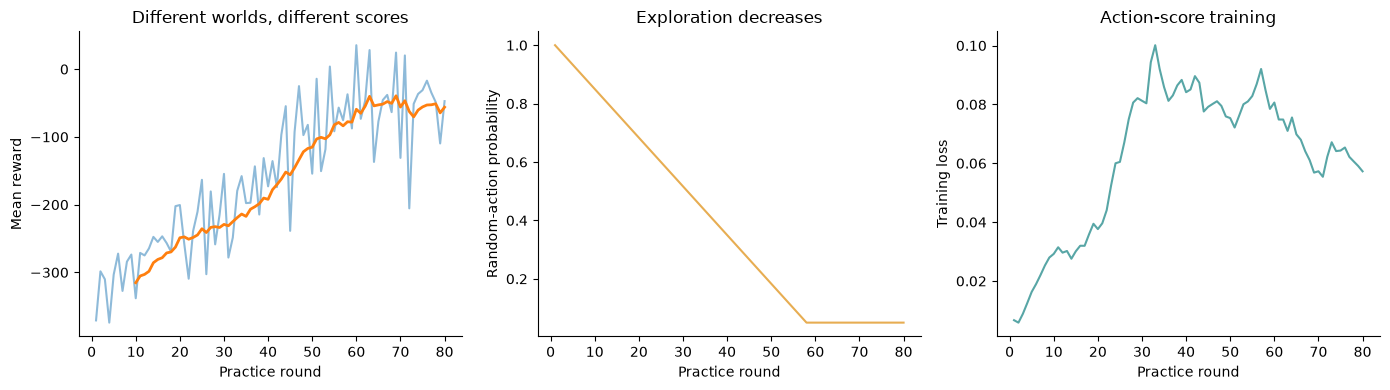

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].plot(training_log['round'], training_log.mean_reward, alpha=.5)
axes[0].plot(training_log['round'], training_log.mean_reward.rolling(10).mean(), linewidth=2)
axes[0].set(xlabel='Practice round', ylabel='Mean reward', title='Different worlds, different scores')
axes[1].plot(training_log['round'], training_log.epsilon, color='#e7ad52')
axes[1].set(xlabel='Practice round', ylabel='Random-action probability', title='Exploration decreases')
axes[2].plot(training_log['round'], training_log.loss, color='#58a6a6')
axes[2].set(xlabel='Practice round', ylabel='Training loss', title='Action-score training')
show_plot('01_dqn_training')

## 4. Compare on separate validation people
No further learning occurs in these evaluation sessions. We compare the final checkpoint, not the best-looking individual practice episode.

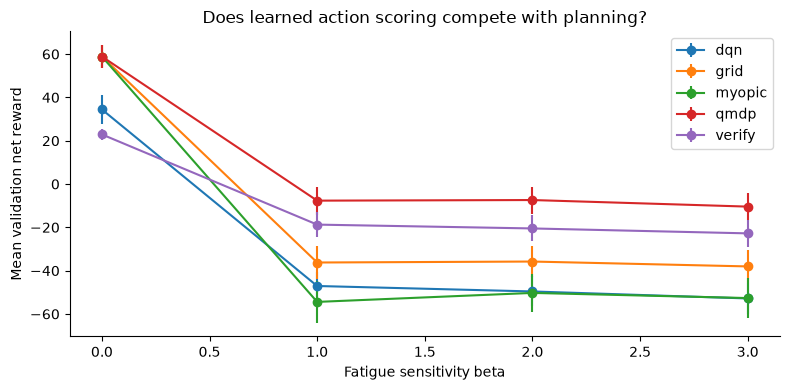

policy,dqn,grid,myopic,qmdp,verify
beta,,,,,
0.0,34.43,58.87,58.87,58.87,22.91
1.0,-47.09,-36.24,-54.43,-7.68,-18.74
2.0,-49.61,-35.79,-50.29,-7.40,-20.51
3.0,-52.84,-38.05,-52.66,-10.43,-22.79


In [5]:
validation_tables = []
for beta in [0., 1., 2., 3.]:
    scenario = Scenario(model='None' if beta == 0 else 'Markov', beta=beta)
    table, path = benchmark(contexts, scenario, ['verify', 'myopic', 'qmdp', 'grid', 'dqn'], dqn=controller, episodes=500)
    table['beta'] = beta
    validation_tables.append(table)
validation = pd.concat(validation_tables, ignore_index=True)
validation.to_csv(folder / 'validation_episodes.csv.gz', index=False)
for policy, group in validation.groupby('policy'):
    summary = group.groupby('beta').reward.agg(['mean', 'sem'])
    plt.errorbar(summary.index, summary['mean'], yerr=summary['sem'] * 1.96, marker='o', label=policy)
plt.xlabel('Fatigue sensitivity beta')
plt.ylabel('Mean validation net reward')
plt.title('Does learned action scoring compete with planning?')
plt.legend()
show_plot('02_dqn_validation')
display(validation.groupby(['beta', 'policy']).reward.mean().unstack().round(2))

## 5. Inspect the actions the learned controller chooses
A DQN that chooses mostly one action can be a poor policy even when its loss looks stable. Keep that result. The selection rule in Notebook 08 compares all three candidates fairly.

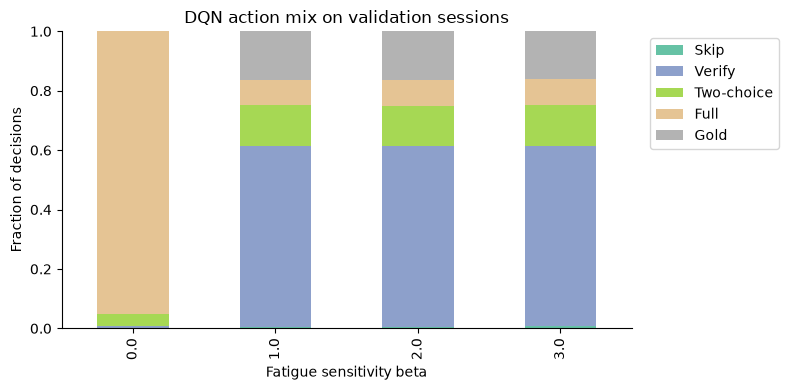

In [6]:
actions = validation[validation.policy == 'dqn'].groupby('beta')[[f'count_{name}' for name in ['skip', 'verify', 'two_choice', 'full', 'gold']]].mean() / 150
actions.columns = ['Skip', 'Verify', 'Two-choice', 'Full', 'Gold']
actions.plot.bar(stacked=True, colormap='Set2')
plt.ylabel('Fraction of decisions')
plt.xlabel('Fatigue sensitivity beta')
plt.title('DQN action mix on validation sessions')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
show_plot('03_dqn_action_mix')